# Station clustering

**Unit:** docked station, keyed on station *name*. Divvy changed its station-id scheme
mid-2025 (numeric `13001` through May, `CHI00214` from June), so ids split one physical
station into two. Names survive the change.

**Features (5):** share of departures in the weekday AM peak (06–08), the weekday PM
peak (16–18), and on weekends; member share; and AM net flow,
`(AM arrivals − AM departures) / (AM arrivals + AM departures)`, which separates
stations bikes *leave* from stations bikes *pile up at*. All are volume-normalised, so
clusters describe behaviour, not size.

**Algorithm:** k-means on standardised features. k chosen at 4 from the elbow.

**Forecast-safe:** a station's cluster is a property of the station, not of a day's
realised ridership, so it can be attached to a date that hasn't happened yet.

In [1]:
import io, os, glob, zipfile, urllib.request
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for parent in [Path.cwd(), *Path.cwd().parents]:
    if (parent / "data").is_dir():
        DATA = parent / "data"; break
else:
    raise FileNotFoundError("data/ not found above " + str(Path.cwd()))

MIN_DEPARTURES = 365      # at least one departure a day on average
SEED = 42
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
pd.set_option("display.width", 200)

## Build or load station profiles

`data/station_profiles.csv` and `data/station_hourly.csv` are committed, so a clean clone
does not download anything. Delete them to rebuild from the twelve 2025 archives (~204 MB,
cached in `data/raw/`, gitignored).

In [2]:
def build_profiles():
    raw = DATA / "raw"; raw.mkdir(exist_ok=True)
    dep, arr, geo, hourly, months = [], [], [], [], []
    for m in range(1, 13):
        z = raw / f"2025{m:02d}-divvy-tripdata.zip"
        if not z.exists():
            print(f"  downloading {z.name} ...")
            urllib.request.urlretrieve(f"https://divvy-tripdata.s3.amazonaws.com/{z.name}", z)
        with zipfile.ZipFile(z) as zf:
            inner = [n for n in zf.namelist()
                     if n.lower().endswith(".csv") and not n.startswith("__MACOSX")]
            assert len(inner) == 1, (z.name, inner)   # inner filenames are unreliable
            with zf.open(inner[0]) as fh:
                t = pd.read_csv(io.TextIOWrapper(fh, "utf-8", errors="replace"),
                    usecols=["started_at","ended_at","start_station_name","end_station_name",
                             "start_lat","start_lng","member_casual"],
                    dtype={"start_station_name":str,"end_station_name":str,"member_casual":str})
        t["started_at"] = pd.to_datetime(t.started_at, format="mixed", errors="coerce")
        t["ended_at"]   = pd.to_datetime(t.ended_at,   format="mixed", errors="coerce")
        t = t[t.started_at.dt.year == 2025]
        s = t.start_station_name.str.strip().replace("", np.nan)
        e = t.end_station_name.str.strip().replace("", np.nan)

        d = t[s.notna()].copy(); d["st"] = s[s.notna()]
        h, dow = d.started_at.dt.hour, d.started_at.dt.dayofweek
        wd = dow < 5
        d["daytype"] = np.where(wd, "weekday", "weekend"); d["hour"] = h
        d["wd_am"]   = (wd & h.between(6, 8)).astype("int32")
        d["wd_pm"]   = (wd & h.between(16, 18)).astype("int32")
        d["weekend"] = (~wd).astype("int32")
        d["member"]  = d.member_casual.eq("member").astype("int32")
        d["dep"] = 1
        dep.append(d.groupby("st")[["dep","wd_am","wd_pm","weekend","member"]].sum())
        geo.append(d.groupby("st").agg(lat=("start_lat","median"),
                                       lng=("start_lng","median"), w=("dep","size")))
        hourly.append(d.groupby(["st","daytype","hour"]).size().rename("rides"))
        months.append(pd.Series(m, index=d.st.unique()))

        a = t[e.notna() & t.ended_at.notna()].copy()
        a["st"] = e[e.notna() & t.ended_at.notna()]
        ah, ad = a.ended_at.dt.hour, a.ended_at.dt.dayofweek
        a["arr_wd_am"] = ((ad < 5) & ah.between(6, 8)).astype("int32")
        arr.append(a.groupby("st")[["arr_wd_am"]].sum())

    prof = pd.concat(dep).groupby(level=0).sum().join(
           pd.concat(arr).groupby(level=0).sum(), how="left").fillna({"arr_wd_am": 0})
    g = pd.concat(geo)
    prof["lat"] = g.groupby(level=0).apply(lambda x: np.average(x.lat, weights=x.w))
    prof["lng"] = g.groupby(level=0).apply(lambda x: np.average(x.lng, weights=x.w))
    prof["months_active"] = pd.concat(months).groupby(level=0).nunique()
    prof.index.name = "station"
    hr = pd.concat(hourly).groupby(level=[0,1,2]).sum().reset_index().rename(columns={"st":"station"})
    prof.to_csv(DATA / "station_profiles.csv"); hr.to_csv(DATA / "station_hourly.csv", index=False)
    return prof.reset_index(), hr

if (DATA / "station_profiles.csv").exists() and (DATA / "station_hourly.csv").exists():
    prof = pd.read_csv(DATA / "station_profiles.csv")
    hr   = pd.read_csv(DATA / "station_hourly.csv")
else:
    prof, hr = build_profiles()

print(f"{len(prof):,} station names | {prof.dep.sum():,} departures from a named station")

1,893 station names | 4,368,271 departures from a named station


## Filter and features

Rides with a blank station name (21.3% of starts — dockless e-bikes left outside a dock)
cannot be attributed to a station and are excluded. Stations are kept if they were active
in all twelve months and averaged at least one departure a day.

In [3]:
keep = prof[(prof.dep >= MIN_DEPARTURES) & (prof.months_active == 12)].set_index("station")
F = pd.DataFrame({
    "am_share":      keep.wd_am / keep.dep,
    "pm_share":      keep.wd_pm / keep.dep,
    "weekend_share": keep.weekend / keep.dep,
    "member_share":  keep.member / keep.dep,
    "am_net":        (keep.arr_wd_am - keep.wd_am) / (keep.arr_wd_am + keep.wd_am).replace(0, np.nan),
})
assert F.notna().all().all(), "null feature values"

print(f"{len(F)} stations kept, {100*keep.dep.sum()/prof.dep.sum():.0f}% of docked departures")
print(F.describe().round(3).to_string())
print("\ncorrelations")
print(F.corr().round(2).to_string())

X = StandardScaler().fit_transform(F.to_numpy())

584 stations kept, 91% of docked departures
       am_share  pm_share  weekend_share  member_share   am_net
count   584.000   584.000        584.000       584.000  584.000
mean      0.115     0.207          0.280         0.646   -0.175
std       0.061     0.061          0.063         0.105    0.436
min       0.005     0.071          0.051         0.177   -0.961
25%       0.070     0.169          0.248         0.607   -0.518
50%       0.106     0.196          0.285         0.667   -0.252
75%       0.154     0.227          0.319         0.710    0.152
max       0.341     0.560          0.502         0.846    0.961

correlations
               am_share  pm_share  weekend_share  member_share  am_net
am_share           1.00     -0.19          -0.29          0.34   -0.61
pm_share          -0.19      1.00          -0.59          0.26    0.65
weekend_share     -0.29     -0.59           1.00         -0.52   -0.33
member_share       0.34      0.26          -0.52          1.00   -0.10
am_net     

## Choosing k

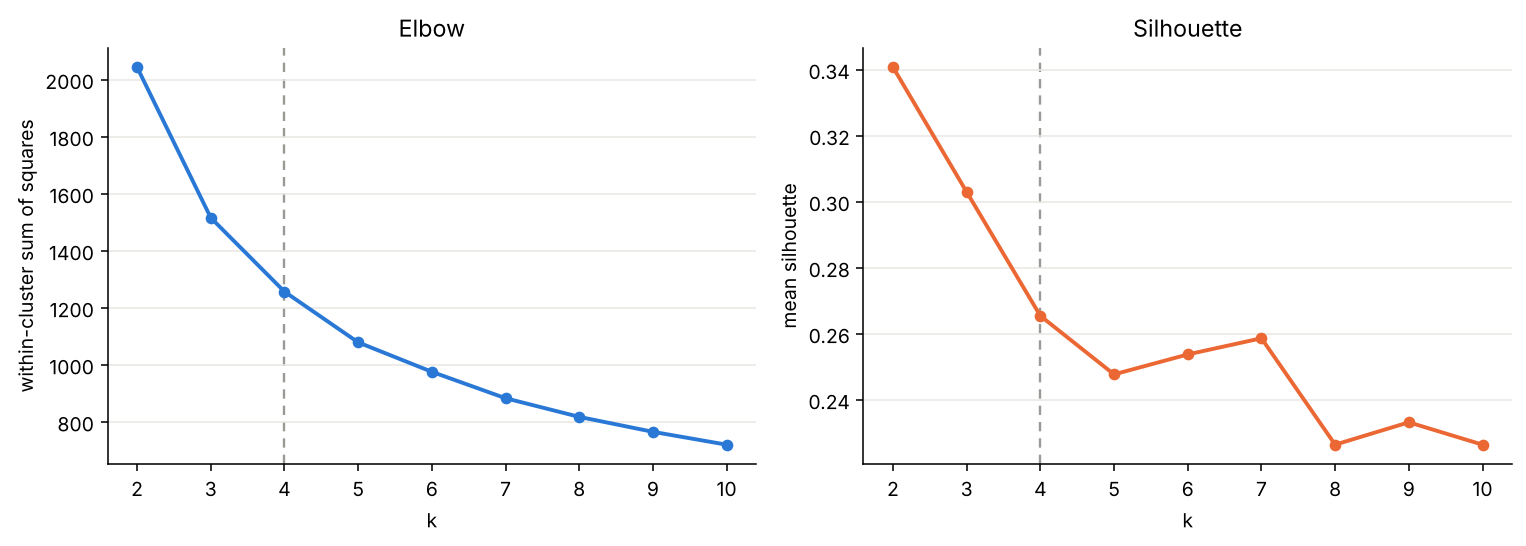

 k  inertia  drop  silhouette
 2   2043.0   NaN       0.341
 3   1516.0 528.0       0.303
 4   1256.0 259.0       0.265
 5   1079.0 178.0       0.248
 6    975.0 103.0       0.254
 7    883.0  93.0       0.259
 8    817.0  65.0       0.226
 9    765.0  52.0       0.233
10    720.0  45.0       0.226


In [4]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4), dpi=140)
ax[0].plot(list(ks), inertia, marker="o", ms=5, color=PAL[0], lw=2)
ax[0].set_xlabel("k"); ax[0].set_ylabel("within-cluster sum of squares"); ax[0].set_title("Elbow")
ax[1].plot(list(ks), sil, marker="o", ms=5, color=PAL[1], lw=2)
ax[1].set_xlabel("k"); ax[1].set_ylabel("mean silhouette"); ax[1].set_title("Silhouette")
for a in ax:
    a.axvline(4, color="#9a9995", ls=(0, (4, 3)), lw=1.2, zorder=0)
    a.grid(axis="y", color="#e8e7e3", lw=.8); a.set_axisbelow(True)
    a.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "drop": [np.nan]+list(np.round(-np.diff(inertia))),
                    "silhouette": np.round(sil, 3)}).to_string(index=False))

Silhouette is highest at k=2 and never exceeds 0.35, which says the structure is a
gradient rather than well-separated islands — stations shade into each other. The elbow
is at k=4: the drop in within-cluster variance falls from 259 to 178 after that and then
flattens. k=4 is taken because it is where the elbow sits and because the four groups
map onto distinct operational handling; k=2 would only separate commuter from
recreational, which is already visible without clustering.

In [5]:
km = KMeans(n_clusters=4, n_init=50, random_state=SEED).fit(X)
F["cluster_id"] = km.labels_
summary = F.groupby("cluster_id").mean()

# name by behaviour, not by k-means' arbitrary label order
leisure  = summary.member_share.idxmin()
rest     = summary.drop(index=leisure)
origin   = rest.am_net.idxmin()
dest     = rest.am_net.idxmax()
mixed    = [i for i in summary.index if i not in (leisure, origin, dest)][0]
NAMES    = {origin: "Morning origin", dest: "Workday destination",
            leisure: "Leisure / lakefront", mixed: "Mixed neighbourhood"}
ORDER    = [NAMES[i] for i in (origin, dest, mixed, leisure)]
COLOR    = dict(zip(ORDER, PAL))

F["cluster"] = F.cluster_id.map(NAMES)
stations = keep.join(F[["cluster"]])
print(F.cluster.value_counts().reindex(ORDER).to_string())

cluster
Morning origin         186
Workday destination     85
Mixed neighbourhood    268
Leisure / lakefront     45


In [6]:
tab = (stations.assign(**{c: F[c] for c in ["am_share","pm_share","weekend_share","member_share","am_net"]})
       .groupby("cluster")
       .agg(stations=("dep","size"), departures=("dep","sum"),
            am=("am_share","mean"), pm=("pm_share","mean"), weekend=("weekend_share","mean"),
            member=("member_share","mean"), am_net=("am_net","mean"))
       .reindex(ORDER).round(3))
tab["share_of_rides"] = (tab.departures / tab.departures.sum()).round(3)
display(tab)

for name in ORDER:
    top = stations[stations.cluster == name].nlargest(4, "dep").index.tolist()
    print(f"{name:<22} {'; '.join(top)}")

,stations,departures,am,pm,weekend,member,am_net,share_of_rides
cluster,,,,,,,,
Morning origin,186,976128,0.176,0.174,0.273,0.683,-0.578,0.245
Workday destination,85,788602,0.095,0.316,0.181,0.707,0.468,0.198
Mixed neighbourhood,268,1840827,0.090,0.201,0.301,0.643,-0.135,0.463
Leisure / lakefront,45,374490,0.049,0.168,0.374,0.390,0.041,0.094


Morning origin         Kingsbury St & Kinzie St; Clark St & Elm St; Wells St & Huron St; Indiana Ave & Roosevelt Rd
Workday destination    Clinton St & Washington Blvd; Canal St & Madison St; Clinton St & Madison St; Clinton St & Jackson Blvd
Mixed neighbourhood    Wells St & Concord Ln; Wells St & Elm St; State St & Chicago Ave; Clark St & Armitage Ave
Leisure / lakefront    DuSable Lake Shore Dr & Monroe St; Michigan Ave & Oak St; DuSable Lake Shore Dr & North Blvd; Millennium Park


## Hourly shape by cluster

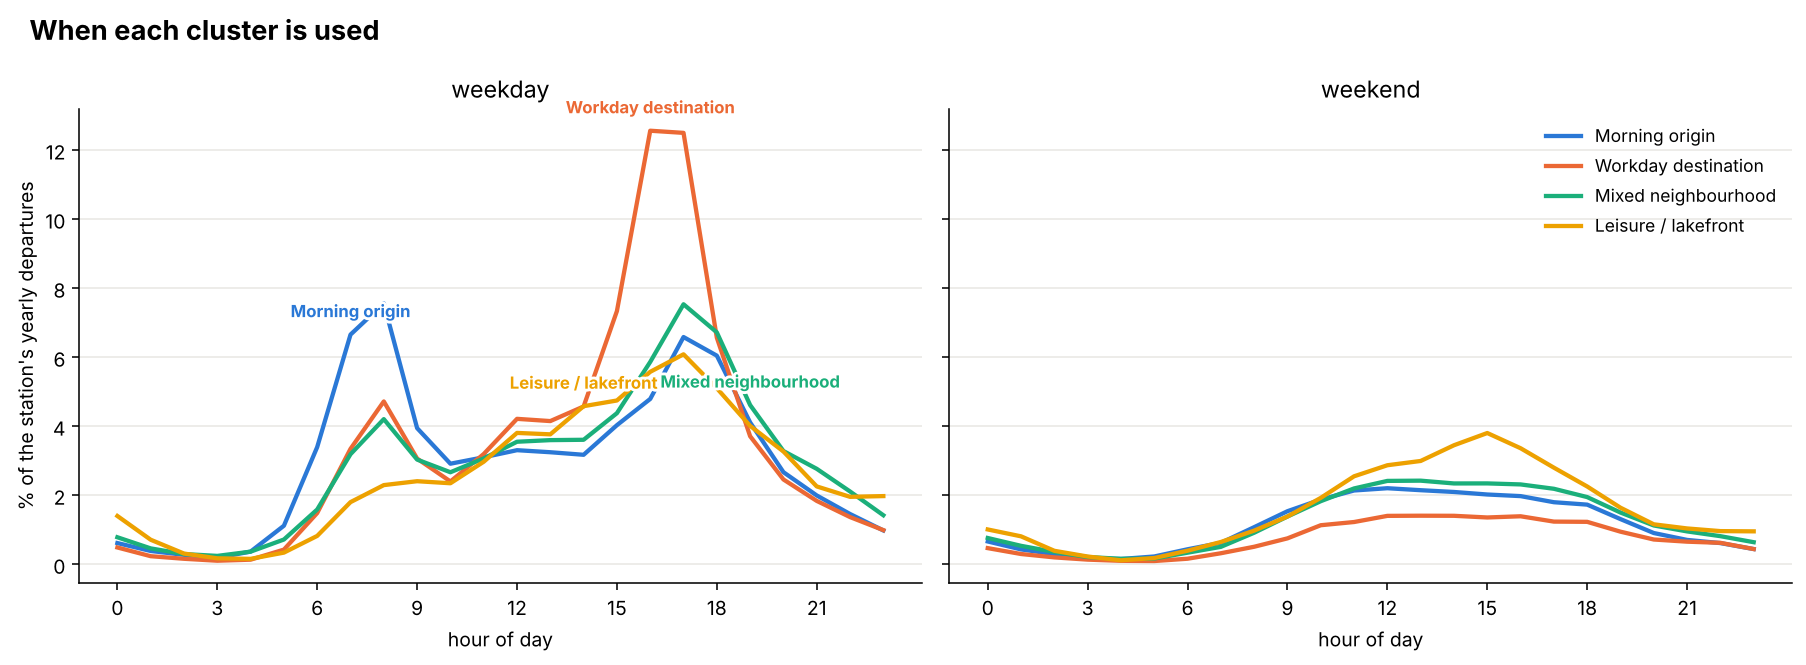

In [7]:
hrk = hr[hr.station.isin(stations.index)].merge(
        stations[["cluster"]], left_on="station", right_index=True)
tot = hrk.groupby("station").rides.transform("sum")
hrk["share"] = hrk.rides / tot
shape = hrk.groupby(["cluster","daytype","hour"]).share.mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=140, sharey=True)
for ax, dt in zip(axes, ["weekday", "weekend"]):
    for name in ORDER:
        d = shape[(shape.cluster == name) & (shape.daytype == dt)].sort_values("hour")
        ax.plot(d.hour, 100*d.share, color=COLOR[name], lw=2.2, label=name)
        if dt == "weekday":
            # label each curve where it stands furthest above the others, so the
            # four labels cannot land on the same hour
            others = (shape[(shape.cluster != name) & (shape.daytype == dt)]
                      .groupby("hour").share.max().reindex(d.hour.values).to_numpy())
            gap = np.where(d.hour.between(5, 20), d.share.to_numpy() - others, -np.inf)
            i = int(np.argmax(gap)); h = int(d.hour.values[i])
            y = float(d.share.to_numpy()[i])
            above = y >= others[i]
            ax.annotate(name, xy=(h, 100*y), xytext=(0, 9 if above else -17),
                        textcoords="offset points", ha="center", fontsize=8.6,
                        color=COLOR[name], weight="bold", zorder=5,
                        path_effects=[pe.withStroke(linewidth=3, foreground="white")])
    ax.set_title(dt); ax.set_xlabel("hour of day"); ax.set_xticks(range(0, 24, 3))
    ax.grid(axis="y", color="#e8e7e3", lw=.8); ax.set_axisbelow(True)
    ax.spines[["top","right"]].set_visible(False)
axes[0].set_ylabel("% of the station's yearly departures")
axes[1].legend(frameon=False, fontsize=9)
fig.suptitle("When each cluster is used", x=0.02, ha="left", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

## Where the clusters are

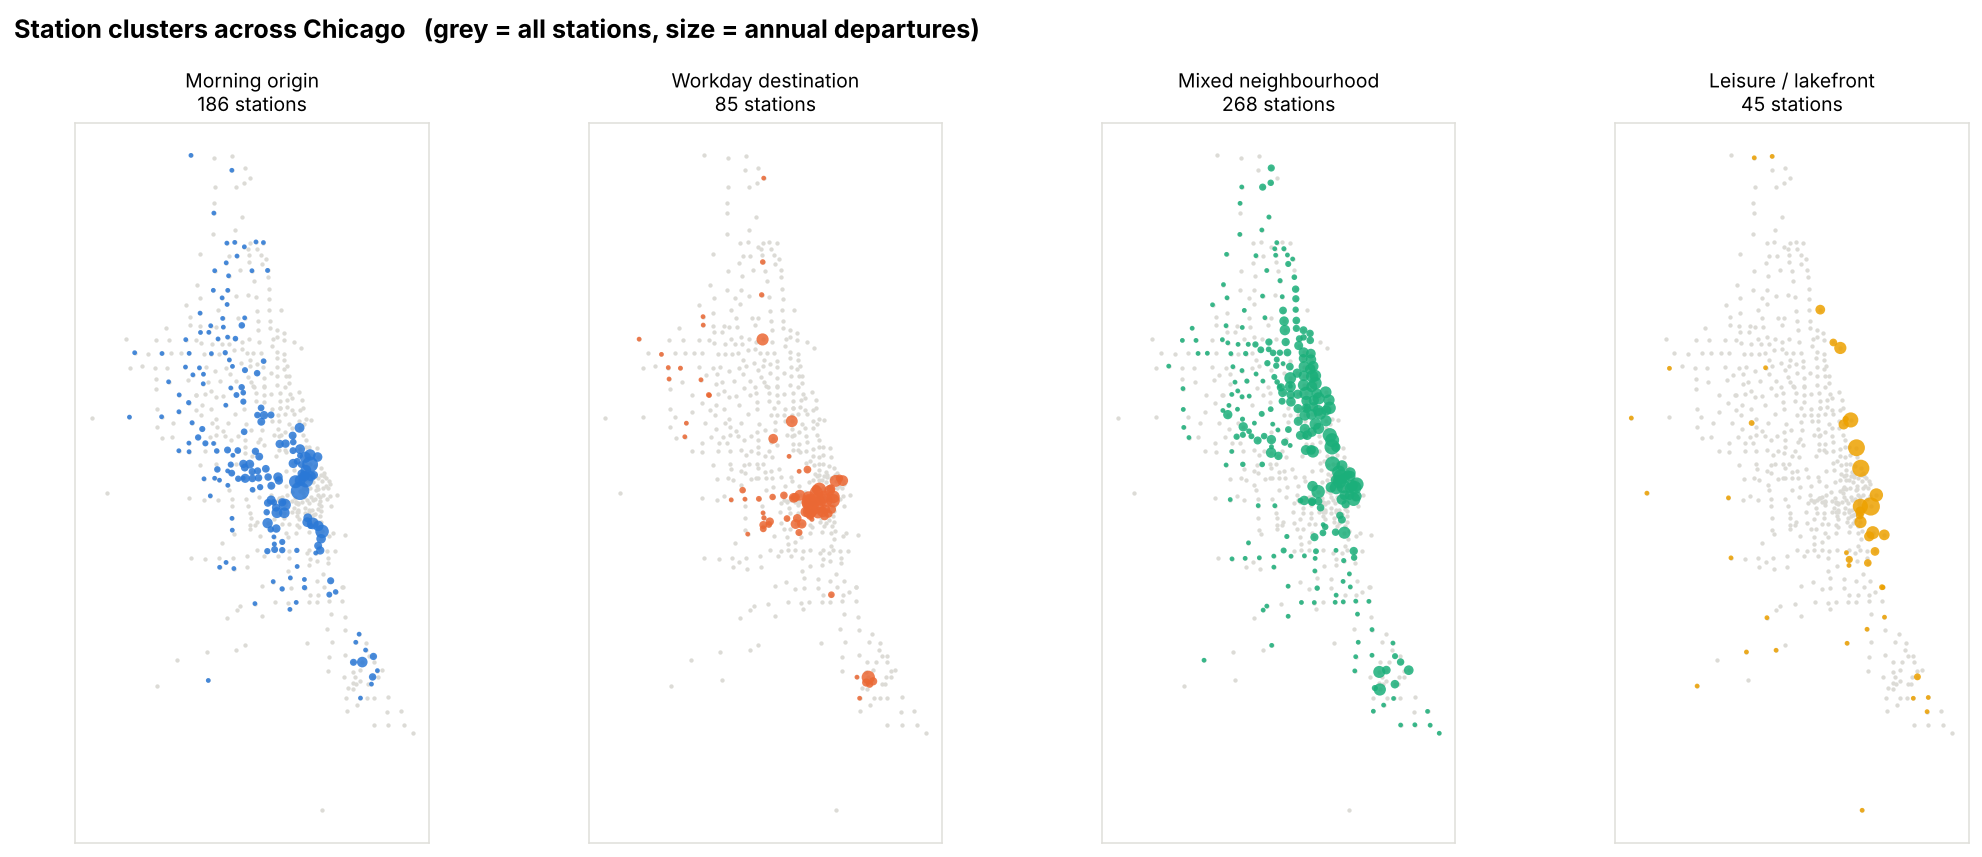

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 6.2), dpi=140, sharex=True, sharey=True)
for ax, name in zip(axes, ORDER):
    sub = stations[stations.cluster == name]
    ax.scatter(stations.lng, stations.lat, s=5, color="#dcdbd6", lw=0, zorder=1)
    ax.scatter(sub.lng, sub.lat, s=np.clip(sub.dep/450, 6, 90),
               color=COLOR[name], alpha=.85, lw=0, zorder=2)
    ax.set_title(f"{name}\n{len(sub)} stations", fontsize=10)
    ax.set_aspect(1/np.cos(np.radians(41.88)))
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_color("#e0dfda")
fig.suptitle("Station clusters across Chicago   (grey = all stations, size = annual departures)",
             x=0.02, ha="left", fontsize=13, weight="bold")
plt.tight_layout(); plt.show()

In [9]:
out = stations[["cluster","dep","wd_am","wd_pm","weekend","member","arr_wd_am","lat","lng"]].copy()
out.to_csv(DATA / "station_clusters.csv")
print(f"wrote data/station_clusters.csv  ({len(out)} stations)")

wrote data/station_clusters.csv  (584 stations)


## Limits

- 21.3% of 2025 starts have no station name and are excluded, so these clusters describe
  docked behaviour only. Dockless e-bike demand is not represented.
- Stations below 365 departures or not active all twelve months are dropped: 584 of 1,893
  names kept, covering 91% of docked departures. The excluded tail is small stations and
  ones that opened or closed mid-year.
- Silhouette peaks at k=2 and is 0.265 at k=4. The clusters are useful groupings along a
  continuum, not sharply separated populations — stations near a boundary could reasonably
  sit either side.
- One year, so a cluster reflects 2025 only. A station that changes character (new office,
  new bike lane) would not be caught.